# Implications of the results

**Status:** extension to the 2027 NFL Big Data Bowl entry, not part of it. GitHub only; not published on Kaggle. Date-stamped 2026-10-19.

The competition entry is frozen at `c652424`. This notebook extends its logic — the three pricing mechanisms, the dollar value to one team, a low-political-cost adoption chunk, team fit, and outreach — and changes none of the judged artifacts.

**Every dollar figure here is an inference, not a measurement.** The measured coefficients are cited with their source files; the valuation assumptions are explicit and ranged. The base case is **$6.6M gross per year**, **$5.6M net** after implementation cost, and **$2.3M expected** at 40% adoption. The high case reaches $11M net; the low case is $0.9M net.


## The finding in one page

The entry's measured result is not "tracking predicts performance." It is that three pricing mechanisms see three different things:

| Mechanism | What it prices | Measured evidence |
|---|---|---|
| The stopwatch | Sacks, not pressure | The 40-yard dash and 10-yard split add nothing to pressure (joint p=0.998); out-of-sample pressure R² is −0.113 for the stopwatch and +0.178 for the 10 Hz burst. |
| The depth chart | Status and prior role | Next-season role: current role +0.606, draft capital +0.785, performance −0.011 (95% CI −0.119 to 0.097, n=233). Concurrent performance is −0.132 (p=0.031), marginal. |
| The cap | Performance, partly role | Full 909-player ledger: performance +0.328 (0.264–0.392); +0.143 (0.078–0.208) with playing time. |

The pure measurement finding: the 10 Hz burst predicts interior pressure at **+0.354 SD/SD** (0.143–0.565, n=64). Top versus bottom burst tercile pressure is **3.83% vs 2.47%** (+1.36 pp); sacks are **0.97% vs 0.35%** (2.7×). The signal is position-specific: DL +0.734, WR +0.366 (p=0.084), OL +0.058, TE +0.093; interaction p=0.0004.

Sources: `outputs/discovery/interior_burst_models.csv`, `interior_burst_validation.csv`, `interior_burst_players.parquet`, `role_allocation_coefficients.csv`, `outputs/salary/pay_model_full.csv`. The allocation gap is descriptive: late picks/UDFAs +0.59 SD, early picks −0.92 SD; the strict tail is 13 player-seasons (12 players). The group-mean decomposition is full 233: role spread 1.462 vs performance 0.046; reliable 192: 1.104 vs 0.106. The writeup's "nine parts" phrasing is not repeated here because it is not traceable to a single sample.


In [1]:

import base64, io, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _load(b64):
    return pd.read_csv(io.StringIO(zlib.decompress(base64.b64decode(b64)).decode()))

bridge = _load("eJxlT0FuxCAMvO9bLGRwAuTaUw/7B4SQu4mUhAiyrfr7GtRD053DeOQxY1MT77EsGSqvnM4l72GDkleWkvJ+lphOkY+Sa5W6bMfKG+9n7KMp1+bu3Jg/heocC4f8EVI8oD7LsT5rOLiEeTnD8B222z1/ASqc8AItPXKjsJ+uAK3INqObXWlHL48RiYydDKH7ZQfGK397i5XFd17Sjey9wAIp6VtlyQ3XpQjjS9coM7YD0KAmmowfnR4awyDRt/flMcsMmREG5f+daCVRk9KmnwFadymb+6+RHHr6Awu2Rf4AwpNqMg==")
sens = _load("eJxtlNuO2yAQhu/zFDwAQfiAD5ertlIr9aLaSr21iJckKMRYmOwqb98ZsDcma0sG84HNP/8M1sN489TIgzLU2I/uXZqbomd9Os+PCAflu2uE8RHhmzJeLngZTB96OEEvD1O3PB/kpKfd6HSP4946p3qv7UD/RERWiDNeQJPRghVNXbaPq6AVa1JE9znLBc2wKVi8Qd9OvtkRv9aNzh7oyzwiOJIHbbS/wxY53BW8m+W1CLvl60+XdD9PhW49JSjuuiawegP9+Lfr7eCd7H03WueP1mhLv82IPFABQdMKm5JlRRph9WwD6hIgvY4yYoNBO2sUpKHXE8Q60VcYks8hGZUj/b03CiOf3y+ZaKCrWIUdfJcnEbQQOhd8fdWwHU/WtNUW+tQzyXdIcBCzd0oaY3sZchEngqxFJCSB0ya4MOsqim1doD6RlWUgNaSqjl7o62jUVQ0+bAYlN3n6K2EkMM7QQDD/i+8lq54IrkUtMQHZXGrroDp1PNLXdZQAoMLV0N/D65w1VECBg0rB2hAc4GfzOCv4k+uctSkqtxDqGXV/mTqwtbsr6ejfW38mgQWrA3sUgGB5mUSJpvMiy4Owok3mGhqRSIXVzZpwsYVQ2Fn7zuijpz+13zvpFcEROTp7Jf6syKRPgzR4/kU4nIJlqEOwJvUnepac1Ta8UeXrTfOoY72s2kIo7SrdRUGBDF45bR35/ptEROIfEGsyw0ZgRaa/AvCreUKgL081o3VlepLymAG+VKyz9qIVHBTsluJsoDjRgir1AJGoQhK5SKPOcHeeCGrzFuGXn9gGQiH/ATPnnHo=")
mc = _load("eJwlkV2O2zAMhN/3LIbB4T9PE2RToVggiQPHXRQ9fSnvi0AJw+HH0WMc+9dteYEuj+Vl51nzfIzrc1727fNy/dy+x+Xf2LeP97iP2/G1PRdaFczOyeEKy/B+CnI15jSDZyEXrCBBUoULgoqnSNIoSsmLCaQtoo99u48umNypMsUALZsGqVpqJQyiDNGF1x7ozsLplFUWU1XQTPTVywhymt6257Ffb0e3YE5vKi2h8m6RFaFQg7CpqNiiK5t33f1KJe5Tk8EeIqIsPf50/b1v73erjRwS3qtZu+ZiayLaM7k9RYElVvTWDJgjjOtHwi7qStlJnX7PcfQkDiHl5sjsDCaNS4VAe8uQxlp8JXj14sxRIp5To6GN69kEVjj9xt9X/9H4dfm+3v/MUDETpEZydDLiMy5CWoobWCvCZqjc4RNJYzRE2VQZsiPiSut//qH9D8csgFs=")

display_bridge = bridge.copy()
display_bridge["share_of_cap"] = (display_bridge["share_of_cap"] * 100).round(1).astype(str) + "%"
print("Scenario table ($M/year):")
print(display_bridge.round(2).to_string(index=False))


Scenario table ($M/year):
scenario  selection_m  role_m  contract_m  gross_m  implementation_cost_m  net_m  ev_m share_of_cap  surplus_per_hit_4y_m
     Low         0.09    0.38        0.90     1.36                    0.5   0.86  0.17         0.3%                  28.8
    Base         0.79    2.10        3.75     6.64                    1.0   5.64  2.26         2.0%                  42.0
    High         2.33    4.80        6.00    13.12                    2.0  11.12  6.68         3.7%                  62.0


### Assumptions

All dollar inputs are in $M/year unless noted. The measured coefficients are not assumptions; they are cited above.

In [2]:
assumptions = pd.DataFrame([('Team cap (context)', '260', '280', '300', '$M'), ('Interior DL market value', '8', '12', '18', '$M/yr'), ('Rookie cost', '0.8', '1.5', '2.5', '$M/yr'), ('Hit-rate lift from the signal', '5%', '15%', '20%', 'probability'), ('Control window', '4', '4', '4', 'years'), ('Such picks per year', '0.25', '0.5', '0.75', 'picks/yr'), ('Role-reallocation saving per decision', '3', '6', '8', '$M/yr'), ('Role decisions per cycle', '0.25', '0.5', '0.75', 'decisions'), ('Reallocation efficiency', '50.0%', '70.0%', '80.0%', 'share'), ('Contract portfolio', '30', '50', '60', '$M/yr'), ('Pricing correction', '3.0%', '7.5%', '10.0%', 'share'), ('Implementation cost', '0.5', '1', '2', '$M/yr'), ('Adoption probability', '20%', '40%', '60%', 'probability')], columns=['Parameter', 'Low', 'Base', 'High', 'Units'])
print(assumptions.to_string(index=False))

                            Parameter   Low  Base  High       Units
                   Team cap (context)   260   280   300          $M
             Interior DL market value     8    12    18       $M/yr
                          Rookie cost   0.8   1.5   2.5       $M/yr
        Hit-rate lift from the signal    5%   15%   20% probability
                       Control window     4     4     4       years
                  Such picks per year  0.25   0.5  0.75    picks/yr
Role-reallocation saving per decision     3     6     8       $M/yr
             Role decisions per cycle  0.25   0.5  0.75   decisions
              Reallocation efficiency 50.0% 70.0% 80.0%       share
                   Contract portfolio    30    50    60       $M/yr
                   Pricing correction  3.0%  7.5% 10.0%       share
                  Implementation cost   0.5     1     2       $M/yr
                 Adoption probability   20%   40%   60% probability


## The valuation model

Three routes, each an annual flow in $M:

- **Selection surplus** = hit-rate lift × (interior DL market value − rookie cost) × such picks per year. The four-year per-pick surplus is $42.0M at base; at a 15% hit-rate lift, the expected surplus is $6.3M per pick over four years. At 0.5 picks per year, the steady-state annual flow is **$0.8M/year**.
- **Role reallocation** = cap saving per decision × decisions per cycle × reallocation efficiency = **$2.1M/year**.
- **Contract pricing** = contract portfolio × pricing correction = **$3.8M/year**.

Gross is the sum; net subtracts the implementation cost; expected value multiplies net by the adoption probability. The routes are not causally additive: if the same organisational change drives both role and contract decisions, the low case is the conservative guide.


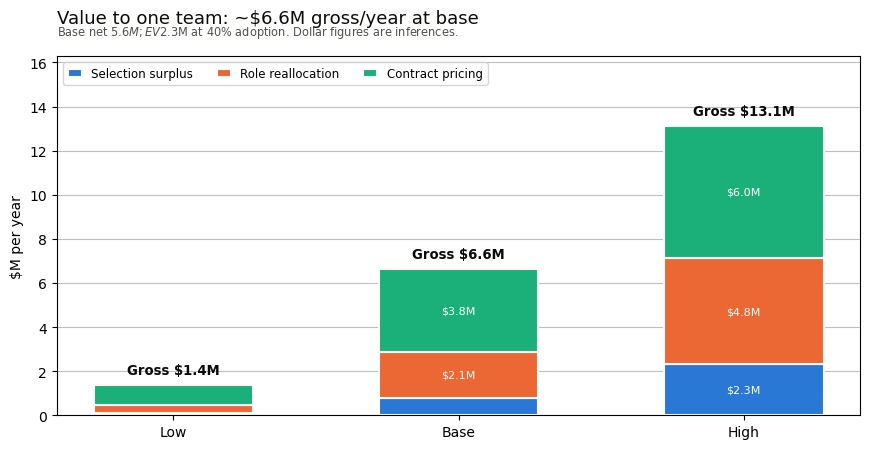

In [3]:

blue, orange, aqua = "#2a78d6", "#eb6834", "#1baf7a"
ink, secondary, surface, baseline = "#0b0b0b", "#52514e", "#fcfcfb", "#c3c2b7"

d = bridge.set_index("scenario").loc[["Low", "Base", "High"]]
fig, ax = plt.subplots(figsize=(8.8, 4.6))
x = np.arange(len(d))
bottom = np.zeros(len(d))
for col, color, label in [
    ("selection_m", blue, "Selection surplus"),
    ("role_m", orange, "Role reallocation"),
    ("contract_m", aqua, "Contract pricing"),
]:
    values = d[col].to_numpy()
    ax.bar(x, values, 0.56, bottom=bottom, color=color, label=label,
           edgecolor=surface, linewidth=1.5)
    for xi, value, base in zip(x, values, bottom):
        if value >= 1.2:
            ax.text(xi, base + value / 2, f"${value:.1f}M", ha="center",
                    va="center", fontsize=8, color="white")
    bottom += values
for xi, total in zip(x, bottom):
    ax.text(xi, total + 0.35, f"Gross ${total:.1f}M", ha="center",
            va="bottom", fontsize=9.5, fontweight="bold", color=ink)
ax.set_xticks(x)
ax.set_xticklabels(d.index)
ax.set_ylabel("$M per year")
ax.set_ylim(0, max(bottom) * 1.24)
ax.grid(axis="y", alpha=0.8)
ax.set_axisbelow(True)
ax.set_title("Value to one team: ~$6.6M gross/year at base", loc="left",
             fontsize=13, color=ink, pad=24)
ax.text(0, 1.045, "Base net $5.6M; EV $2.3M at 40% adoption. "
        "Dollar figures are inferences.", transform=ax.transAxes,
        fontsize=8.2, color=secondary, va="bottom")
ax.legend(loc="upper left", ncol=3, fontsize=8.5, handlelength=1.2)
fig.tight_layout()
plt.show()


## Sensitivity

The largest driver is the **pricing correction** (a swing of $3.5M/year between its low and high values), followed by the contract portfolio, role decisions, and the role-reallocation saving. The selection route is smaller: even at the high case it is $2.3M/year, because the signal's hit-rate lift is applied to a late-pick surplus.

The Monte Carlo treats inputs as independent. Net value P10/P50/P90 is **$3.3M / $4.6M / $6.0M**; expected value is **$1.1M / $1.8M / $2.6M**. The deterministic low/high is the wider stress range; the Monte Carlo is narrower because independent draws average out.


                                label  low_net_m  high_net_m  swing_m
                   Pricing correction       3.39        6.89     3.50
                   Contract portfolio       4.14        6.39     2.25
             Role decisions per cycle       4.59        6.69     2.10
Role-reallocation saving per decision       4.59        6.34     1.75
                  Implementation cost       6.14        4.64    -1.50
              Reallocation efficiency       5.04        5.94     0.90
                  Such picks per year       5.24        6.03     0.79
        Hit-rate lift from the signal       5.11        5.90     0.79
             Interior DL market value       5.34        6.09     0.75
                          Rookie cost       5.69        5.56    -0.13


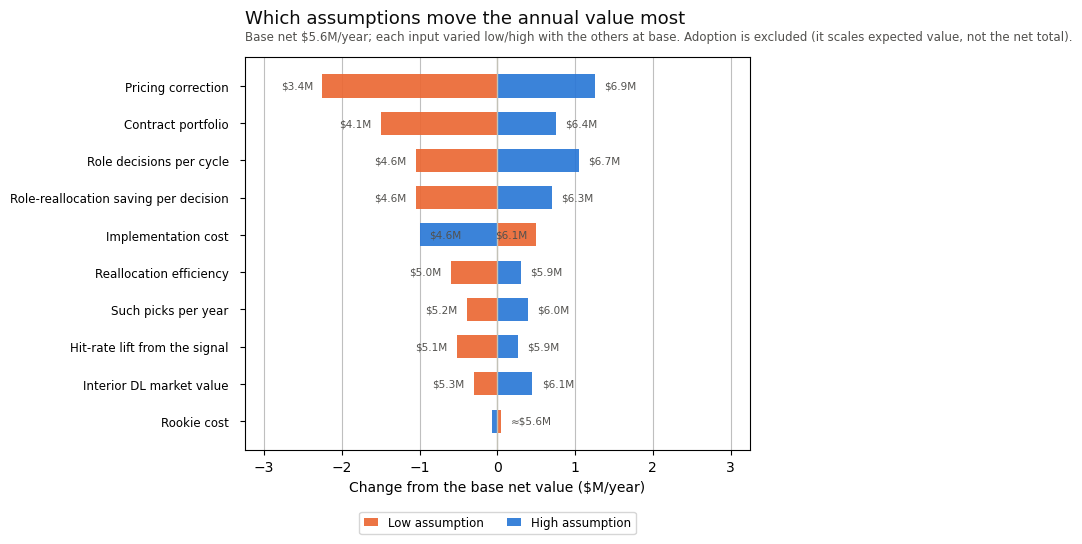

In [4]:

s = sens[sens["basis"].eq("net")].copy()
base_net = float(bridge.set_index("scenario").loc["Base", "net_m"])
s["low_delta"] = s["low_net_m"] - base_net
s["high_delta"] = s["high_net_m"] - base_net
print(s.sort_values("abs_swing_m", ascending=False)[
    ["label", "low_net_m", "high_net_m", "swing_m"]
].round(2).to_string(index=False))
s = s.sort_values("abs_swing_m", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.0, 5.6))
y = np.arange(len(s))
ax.barh(y, s["low_delta"], color=orange, alpha=0.92, label="Low assumption", height=0.62)
ax.barh(y, s["high_delta"], color=blue, alpha=0.92, label="High assumption", height=0.62)
for yi, low, high, low_total, high_total in zip(
    y, s["low_delta"], s["high_delta"], s["low_net_m"], s["high_net_m"]
):
    if abs(high - low) < 0.6:
        ax.text(max(low, high) + 0.12, yi, f"≈${(low_total + high_total) / 2:.1f}M",
                ha="left", va="center", fontsize=7.5, color=secondary)
        continue
    if abs(low) > 0.05:
        ax.text(low - 0.12, yi, f"${low_total:.1f}M", ha="right",
                va="center", fontsize=7.5, color=secondary)
    if abs(high) > 0.05:
        ax.text(high + 0.12, yi, f"${high_total:.1f}M", ha="left",
                va="center", fontsize=7.5, color=secondary)
ax.axvline(0, color=baseline, lw=1.0)
ax.set_yticks(y)
ax.set_yticklabels(s["label"], fontsize=8.5)
ax.tick_params(axis="y", pad=8)
span = max(abs(s["low_delta"].min()), abs(s["high_delta"].max()))
ax.set_xlim(-span - 1.0, span + 1.0)
ax.set_xlabel("Change from the base net value ($M/year)")
ax.grid(axis="x", alpha=0.8)
ax.set_axisbelow(True)
ax.set_title("Which assumptions move the annual value most", loc="left",
             fontsize=13, color=ink, pad=24)
ax.text(0, 1.035, "Base net $5.6M/year; each input varied low/high with the others at base. "
        "Adoption is excluded (it scales expected value, not the net total).",
        transform=ax.transAxes, fontsize=8.5, color=secondary, va="bottom")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2,
          fontsize=8.5, handlelength=1.2)
fig.tight_layout()
plt.show()


In [5]:

print("Monte Carlo summary ($M/year):")
print(mc.round(2).to_string(index=False))


Monte Carlo summary ($M/year):
        metric  p10_m  p50_m  p90_m  mean_m  prob_above_zero
     selection   0.41   0.71   1.10    0.74              1.0
          role   1.21   1.84   2.64    1.89              1.0
      contract   2.12   3.17   4.26    3.19              1.0
         gross   4.51   5.82   7.13    5.82              1.0
           net   3.27   4.64   6.02    4.65              1.0
expected_value   1.14   1.80   2.62    1.85              1.0


## What would make it zero

| Lever | Breakeven | Base | Interpretation |
|---|---:|---:|---|
| Hit-rate lift | 0 pp | 15 pp | The selection surplus disappears. |
| Role saving per decision | $0 | $6M | Guarantees and dead money block the reallocation. |
| Pricing correction | 0% | 7.5% | The market already prices role-controlled performance. |
| Implementation cost | $6.6M | $1.0M | Cost consumes the gross value. |
| Adoption probability | 0% | 40% | No one acts on the analysis. |
| Contract coefficient | 0 | +0.143 | The 95% CI includes 0.078, so the true correction may be small. |

Zero is a scenario, not a forecast. The low case is the conservative guide if the routes overlap.


## Adoption: a low-political-cost chunk

The chunk is not "fire the coach" or "reallocate every snap." It is:

1. Add the burst signal to the interior-DL draft board as one input alongside tape, college production, and draft slot.
2. In obvious pass-rush sub-packages, give a high-burst, low-cost interior lineman 10–15% more snaps and a low-burst, high-cap veteran 10–15% fewer. The veteran loses pass-rush snaps, not starting status or pay.
3. Price the next interior-DL contract on role-controlled performance (+0.143) rather than the raw performance coefficient (+0.328).

**Who loses:** the low-burst veteran loses snaps; the coach loses some discretionary authority; the incumbent scout loses the comfort of the stopwatch. That is why this is **Pareto-adjacent**, not strictly Pareto efficient.

Team archetypes (staffing as of 2026-10-19; source: Wikipedia's current NFL general manager and head coach lists; verify before any outreach):

| Team | GM | Head coach | Why the structure fits | Caveat |
|---|---|---|---|---|
| Titans | Mike Borgonzi | Robert Saleh | New regime, defensive coach, rebuild, high draft capital; interior pressure is a live need. | GM and coach may be aligned, lowering the "challenge the coach" tension. |
| Browns | Andrew Berry | Todd Monken | Most analytics-native GM; cap reset; the cap-versus-role frame is directly salient. | Ownership and the Watson contract constrain a clean reallocation. |
| Jaguars | James Gladstone | Liam Coen | Young, analytics-forward regime with a draft-and-develop mandate. | Not a full rebuild; pressure to win now. |
| Falcons | Ian Cunningham | Kevin Stefanski | New regime; roster and cap reset; authority to re-price roles. | Both are new together, so the wedge is a design choice, not a live conflict. |
| Dolphins | Jon-Eric Sullivan | Jeff Hafley | New regime, defensive coach, clean slate. | The teardown may take precedence over fine-grained role allocation. |
| Cardinals | Monti Ossenfort | Mike LaFleur | Patient, draft-heavy GM; new coach; young roster. | The fit is structural, not a claim about personal analytics views. |

**First-mover caveat:** this is a transition rent, not a permanent edge. If every team adopts the principle, the market re-prices and the surplus flows to players. The window is plausibly 2–5 years.


## Outreach

Target roles, not personal addresses:

| Audience | Example titles | Why | Ask |
|---|---|---|---|
| Club football research / analytics | Director of Football Research, Senior Data Scientist | They read this for a living and can test the signal on their own board. | 15 minutes of feedback; a pointer to the right person. |
| Cap / contract staff | Salary Cap Analyst, Manager of Football Administration | The role-controlled coefficient is a contract argument. | Whether the valuation matches their model. |
| Tracking vendors | Product/research lead, football analytics | The burst-versus-stopwatch result is their product thesis. | Whether the metric is adoptable. |
| League office | Football operations / management council analyst | The rookie-scale and role-pipeline question is system-level. | Whether the allocation gap is a policy question. |
| Analytics media | The Athletic, ESPN analytics, PFF | They can cite public work after the competition. | A conversation after the deadline. |

Use LinkedIn or public team contact routes; do not scrape personal emails. A warm introduction is worth more than ten cold emails.

**Template (under 150 words):**

> Subject: 10 Hz Combine burst predicts interior pressure; the stopwatch doesn't
>
> I'm an independent researcher; this is a 2027 Big Data Bowl entry. Three findings:
> 1. The 10 Hz burst predicts interior pressure (+0.354 SD/SD, n=64); the 40 and 10-yard split do not (OOS R² −0.113 vs +0.178).
> 2. The cap pays performance (+0.328, +0.143 with role); next-season playing time does not detectably (+0.606 current role, +0.785 draft, −0.011 performance).
> 3. The performance-role gap is mostly role; the strict tail is a 12-player review list.
>
> Writeup: [link]. Repo/notebook: [link].
> If this is useful, I'd value 15 minutes of feedback or a pointer to the right person on your research or cap team.

**What not to do:** no mass email; no personal addresses; no causal claims; no promised savings; no claim of team endorsement; no raw data; no Kaggle publication during the competition; no "Pareto efficient" without naming who loses.


## What this is not

- Not a causal identification. The pressure and role results are associations; the agent model is model-reproduced.
- Not investment advice or a contract recommendation.
- Not a validated tool. The pressure sample is 64 interior player-seasons; the strict tail is 13 player-seasons.
- Not a redistribution of competition data. Only derived summary numbers appear here; the raw data is CC BY-NC 4.0 and is not copied.
- Not part of the judged entry. `writeup/`, `notebooks/02_final_public.ipynb`, and the Kaggle metadata are unchanged.


## Reproduce

```bash
python implications/code/value_model.py
python implications/code/figures.py
python implications/code/build_notebook.py
jupyter nbconvert --execute --to notebook --inplace implications/code/implications.ipynb
```

`value_model.py` writes the three CSV tables to `implications/outputs/` (gitignored). `figures.py` writes the two PNGs to `implications/writeups/figures/`. The notebook embeds the tables and runs without `implications/outputs/`.
